# Example: generate time series from your own data

This notebook demonstrates conditional time-series generation with random convolutional feature matching. For a self-contained example, we simulate the observed path using the paper's TGH process. Replace the simulation cell with your own data loader.

In [1]:
import subprocess
import sys

import matplotlib.pyplot as plt
import torch

from sock.paths import data_dir, project_root
from sock.utils import StandardScaler

ROOT = project_root()

## 1. Provide an observed path

For your own dataset, replace this cell with `path = ...`, a time-ordered array of shape `[time, channels]`. The rest of the notebook uses only `path`.

In [2]:
# Demo data: one simulated path with three channels.
import numpy as np
from sock.data.varp import VARpSimulator, tgh_transform

r = omega = 0.8
eye = np.eye(3)
lags = {5: eye * (2 * r * np.cos(omega * np.pi)), 10: eye * (-r**2)}
simulator = VARpSimulator(n_steps=4096, lags=lags, rng=np.random.default_rng(0))
raw = torch.from_numpy(simulator.simulate(1, burn=256)[0])
path = tgh_transform(raw, g=-0.2, h=0.2)

## 2. Split and save

Split the path chronologically into train and test periods. Standardize using the training period only.

In [3]:
DATASET = 'example_real_data'
H = 2048  # end of the training period

path = torch.as_tensor(path, dtype=torch.float32)
assert path.ndim == 2 and len(path) > H

scaler = StandardScaler().fit(path[:H])
train_path = scaler.transform(path[:H])
test_path = scaler.transform(path[H:])

dataset_dir = data_dir() / DATASET
dataset_dir.mkdir(parents=True, exist_ok=True)
torch.save({'train/path': train_path, 'val/path': test_path},
           dataset_dir / f'{DATASET}.pt')
print(f'Train: {train_path.shape}, test: {test_path.shape}')

Train: torch.Size([2048, 3]), test: torch.Size([2048, 3])


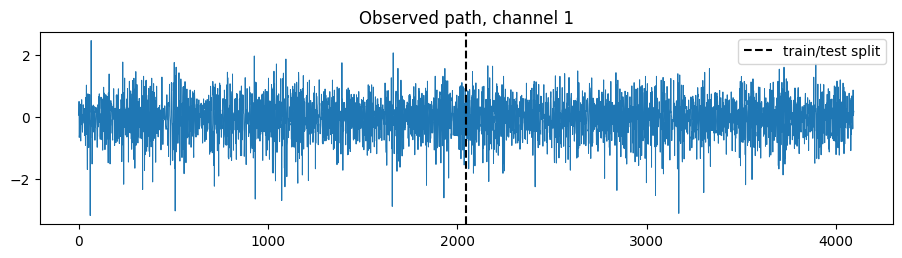

In [4]:
plt.figure(figsize=(11, 2.5))
plt.plot(path[:, 0], lw=0.7)
plt.axvline(H, color='black', ls='--', label='train/test split')
plt.title('Observed path, channel 1')
plt.legend()
plt.show()

## 3. Train the generator

This example uses a short training run.

In [5]:
OPT_STEPS = 10000
log_dir = ROOT / 'logs' / DATASET

subprocess.run([
    sys.executable, 'scripts/train.py',
    '--dataset', DATASET, '--dataset-type', 'real',
    '--opt-steps', str(OPT_STEPS), '--bs', '128',
    '--log-dir', str(log_dir), '--save-paths',
], cwd=ROOT, check=True, capture_output=True)

run_dir = max(log_dir.glob('run-*'), key=lambda p: p.stat().st_mtime)
print(f'Outputs: {run_dir}')

Outputs: /rds/general/user/kjm23/home/projects/rconv_staging/logs/example_real_data/run-20261007-171829


## 4. Inspect the results

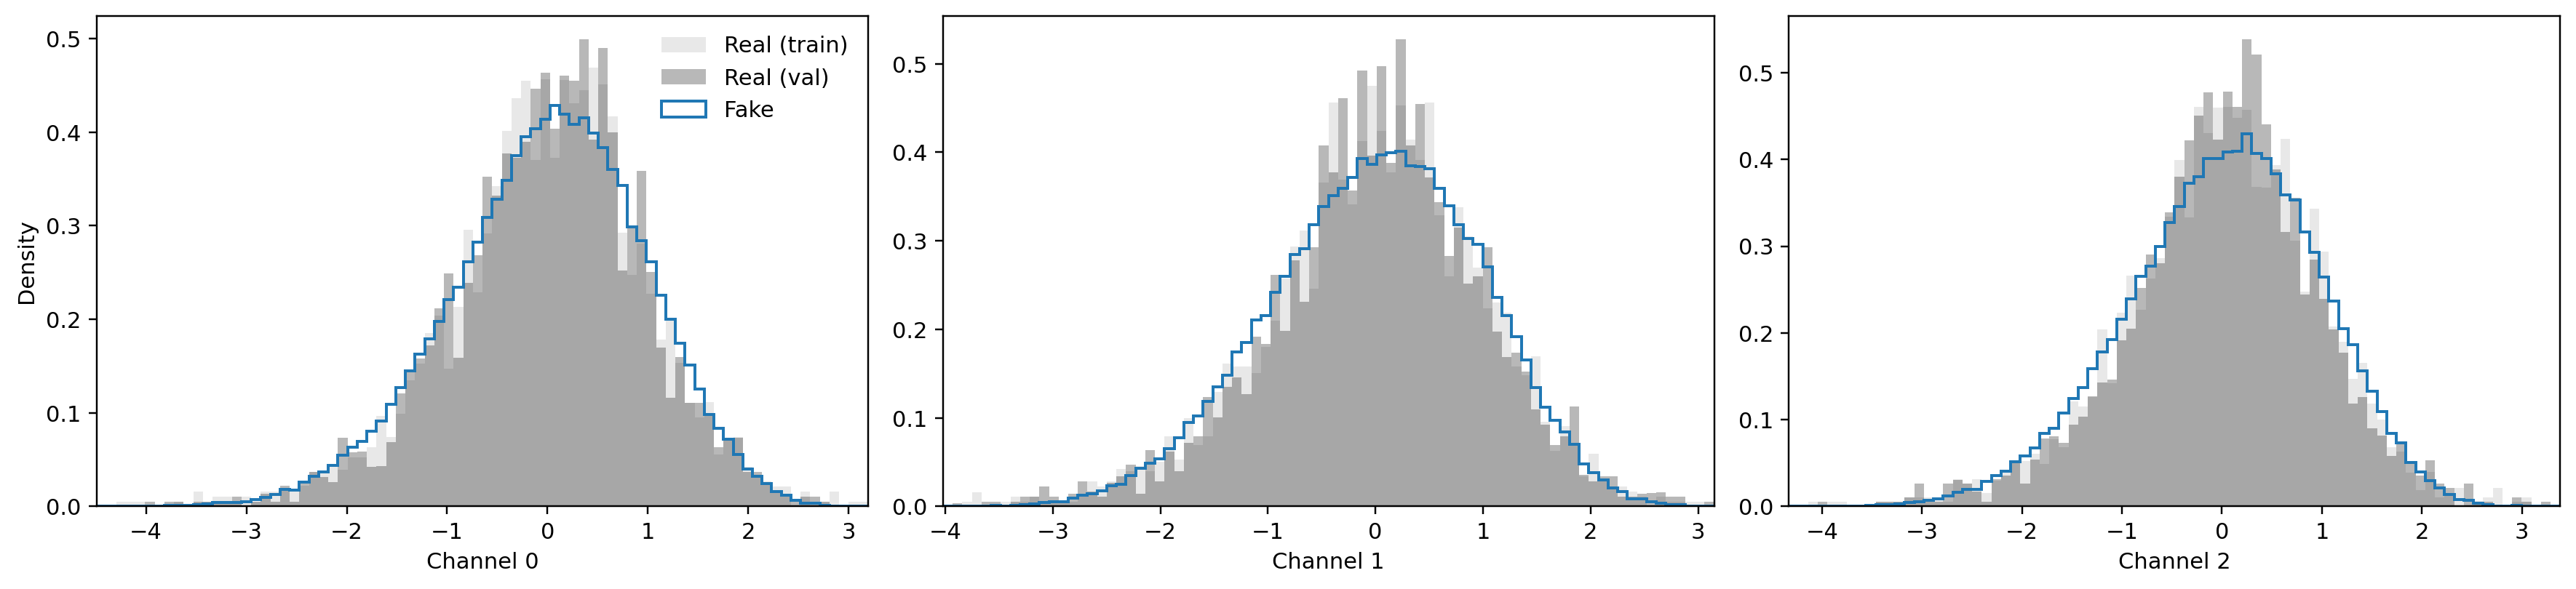

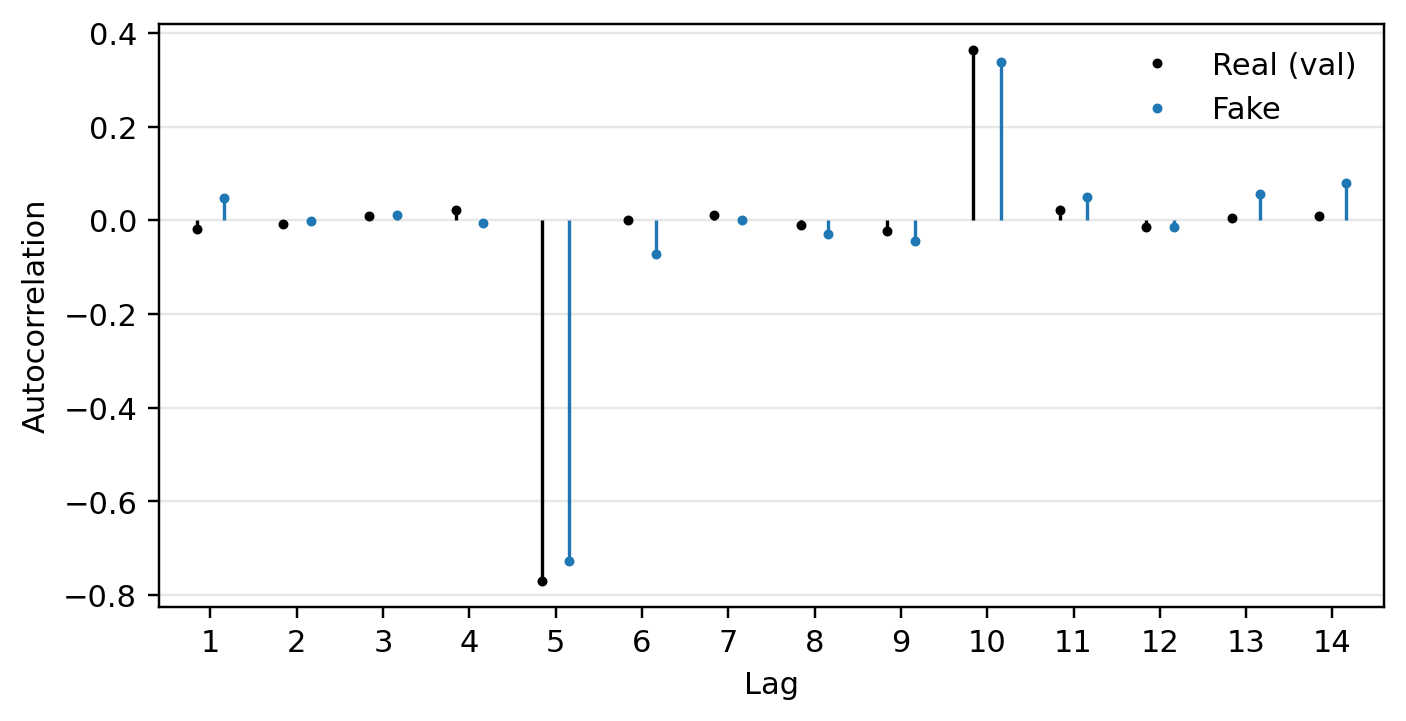

In [6]:
from IPython.display import Image, display

for filename in ('real_vs_fake_paths_marginals.png', 'real_vs_fake_paths_acf.png'):
    display(Image(filename=str(run_dir / filename)))